# **Final Year Project - Year 4 Software Development**
## Iteration 2 - Onset Detection Refinement

*By Mark Lambert - C00192497*

*3/11/2026*

---

This notebook aims to refine the onset detection algorithm to be more precise. The logic from `get_chords()` in `../fretwave/chord_detect.py` is extracted and analysed

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

In [2]:
clip, sr = librosa.load("../data/clips/sample/damdm-jag_neck.wav", sr=None)

In [3]:
# Same logic as get_chords() in chord_detect.py
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
chroma = librosa.feature.chroma_cqt(y=clip, sr=sr)
onset_frames = np.append(onset_frames, chroma.shape[1])

strum_group = [onset_frames[0]]
buffer = 0.5
for i in range(1, len(onset_frames)):
    prev = onset_frames[i-1]
    cur = onset_frames[i]

    frame_since_last = cur - prev
    if librosa.frames_to_time(frame_since_last, sr=sr) > buffer:
        strum_group.append(cur)

raw_times = librosa.frames_to_time(onset_frames, sr=sr)
strum_times = librosa.frames_to_time(strum_group, sr=sr)

print(f"Raw onsets: {len(onset_frames)}")
print(f"Strum group onsets: {len(strum_group)}")

Raw onsets: 20
Strum group onsets: 4


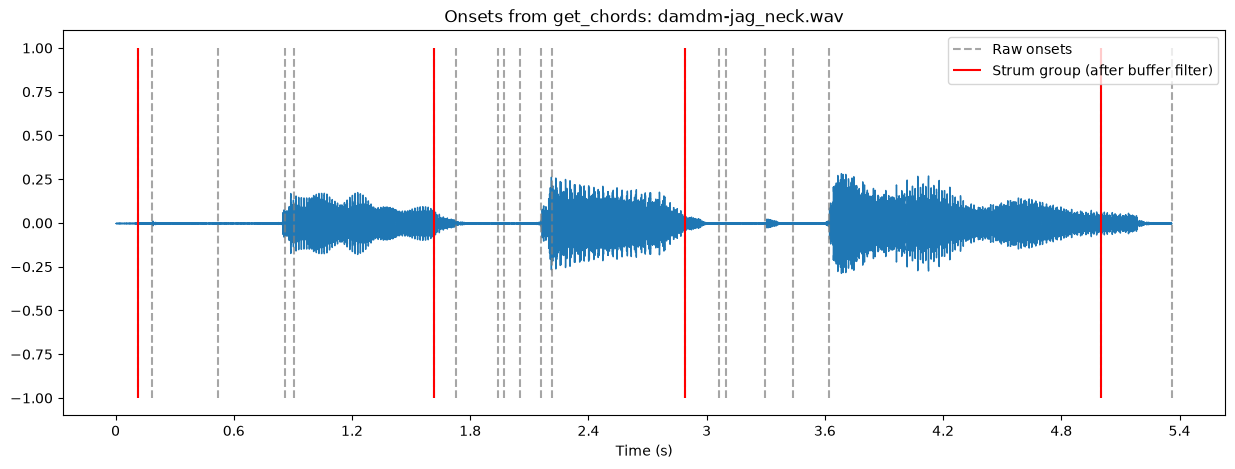

In [4]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(strum_times, -1, 1, color="red", linestyle="-", label="Strum group (after buffer filter)")

ax.set_title("Onsets from get_chords: damdm-jag_neck.wav")
ax.set_xlabel("Time (s)")
ax.legend()
plt.show()

### Analysis

The grey lines are the raw onsets from `onset_detect`, red lines are the onsets left over after the 0.5s buffer filter in `get_chords`

- The clip has three strums, starting at about 0.85s, 2.2s and 3.6s
- None of the red lines are on a strums beginning
- The first onset is always kept, even when it is just noise
- The filter only looks at the gap between onsets. If the gap is more than 0.5s, it keeps the onset. It doesn't check whether the onset is a strum
- The real strums get thrown out when there is another onset less than 0.5s before them
- The line at the very end is the extra frame added with `np.append`

### Issue

The filter relies on the gaps between raw onsets, but the raw onsets include a lot of noise. The onsets I keep need to be at the start of each strum, so the filter needs to look at the audio itself and not just the gaps

This explains the issues that were occuring in the first iteration when using the chord prompt notebook, where additinal chords were being detected 

_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

Because my onset detection has a flaw in detecting the beginning of a chord, I had to research how to find the change in energy. Librosa have a [root-means squared](https://librosa.org/doc/0.10.2/generated/librosa.feature.rms.html) feature, allowing to detect the energy over the course of the audio clip. There is also an example program that touches on using RMS to manipulate onsets in the [onset_backtrack](https://librosa.org/doc-playground/0.7.2/_modules/librosa/onset.html#:~:text=def-,onset%5Fbacktrack) function 

[Text(0.5, 1.0, 'log Power spectrogram')]

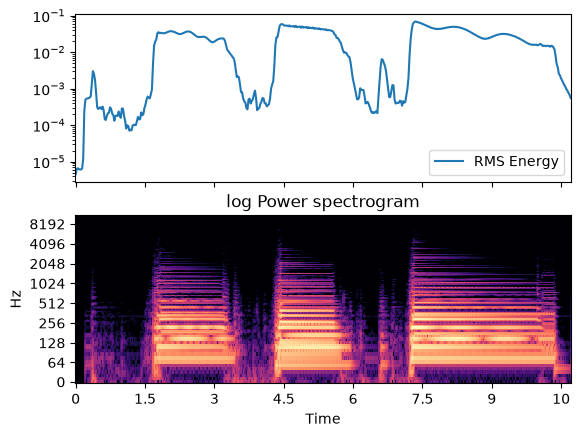

In [5]:
y, sr = librosa.load('../data/clips/sample/damdm-jag_neck.wav', sr=None)
S, phase = librosa.magphase(librosa.stft(y))
rms = librosa.feature.rms(S=S)

fig, ax = plt.subplots(nrows=2, sharex=True)
times = librosa.times_like(rms)

ax[0].semilogy(times, rms[0], label='RMS Energy')
ax[0].set(xticks=[])
ax[0].legend()
ax[0].label_outer()
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
                         y_axis='log', x_axis='time', ax=ax[1])
ax[1].set(title='log Power spectrogram')

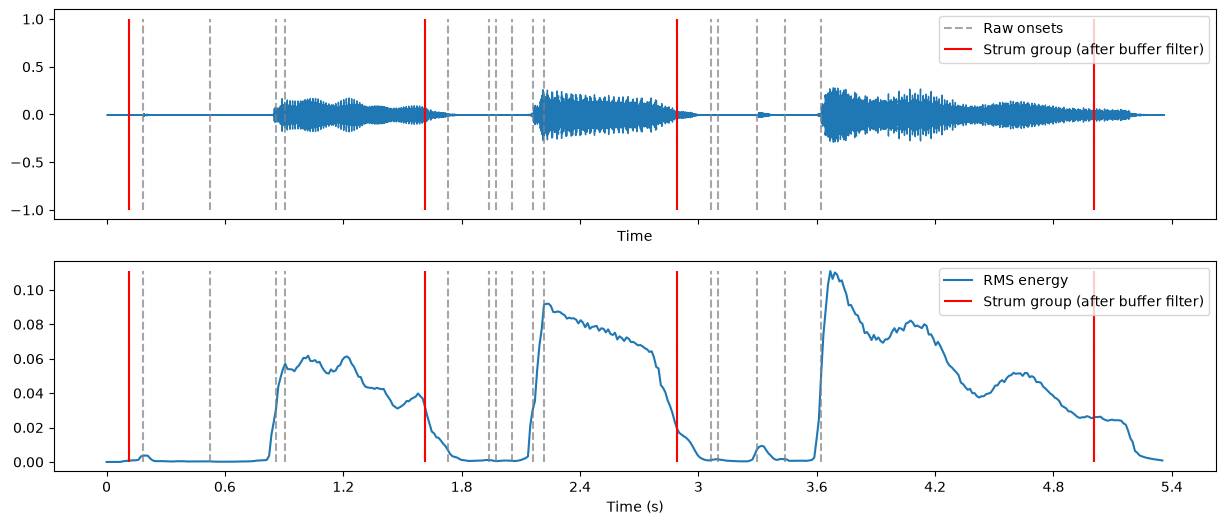

In [6]:
rms = librosa.feature.rms(y=clip)[0]
rms_times = librosa.times_like(rms, sr=sr)

raw_onsets = librosa.onset.onset_detect(y=clip, sr=sr)
raw_onset_times = librosa.frames_to_time(raw_onsets, sr=sr)

fig, ax = plt.subplots(nrows=2, sharex=True, figsize=(15, 6))

librosa.display.waveshow(clip, sr=sr, ax=ax[0])
ax[0].vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax[0].vlines(strum_times, -1, 1, color="red", linestyle="-", label="Strum group (after buffer filter)")
ax[0].legend()

ax[1].plot(rms_times, rms, label="RMS energy")
ax[1].vlines(raw_onset_times, 0, rms.max(), color="grey", linestyle="--", alpha=0.7)
ax[1].vlines(strum_times, 0, rms.max(), color="red", linestyle="-", label="Strum group (after buffer filter)")
ax[1].set_xlabel("Time (s)")
ax[1].legend()

plt.show()

_____________________________________________________
To filter out ambient noise that cause onsets, setting a threshold on the valid level is done by multiplying the max of the root mean squared of the clip by `0.2`

Each frame is then iterated through from the onsets, and the current frame must be above the `valid_threshold` mentioned **and** the current frame must be `1.5` times louder than the previous frame

If both conditions are satisfied, the frames are marked as true chord strums

In [7]:
rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)

valid_threshold = 0.2 * rms.max()
frame_offset = 2
attacks = []

for frame in onset_frames:
    # get the frame number for each valid energy wave 
    # curr is the rms value for current frame
    curr = rms[frame]
    # prev is rms value for current frame - 2 frames
    prev = rms[frame - frame_offset]

    # check if above valid threshold (filter noise) and
    # curr is 1.5 times louder than preevious, then its the start of a strum
    if curr > valid_threshold and curr > 1.5 * prev:
        attacks.append(frame)
attack_onsets = librosa.frames_to_time(attacks, sr=sr)

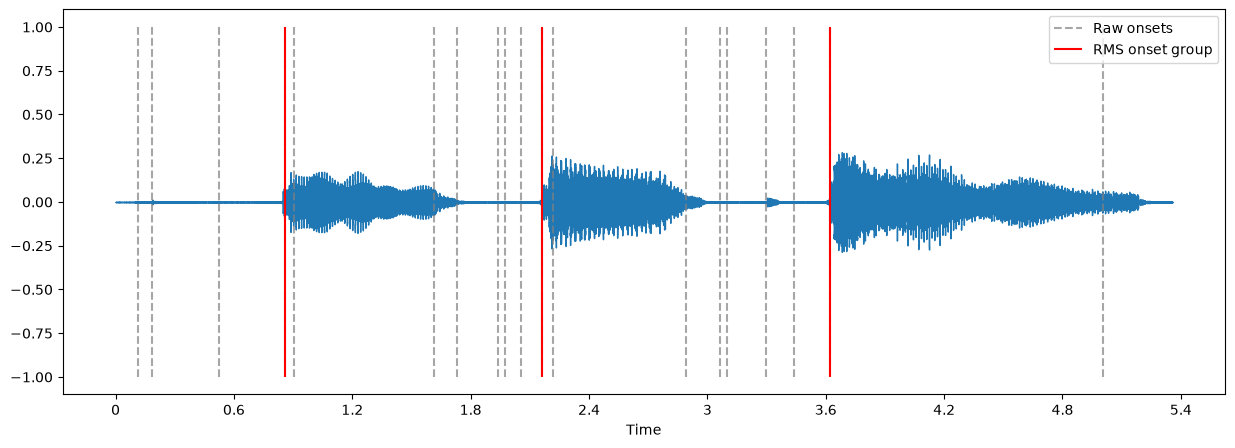

In [8]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(attack_onsets, -1, 1, color="red", linestyle="-", label="RMS onset group")
ax.set_xlabel("Time")
ax.legend()
plt.show()

Plotting the new onsets that were marked by iterating through the result of `librosa.feature.rms` shows the accuracy of using Root Mean Square to identify frames above a certain loudness as chord strums

The next steps are to combine this rms function with the existing onset detection to isolate where the chord finishes and the transition begins

In [9]:
rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
valid_threshold = 0.2 * rms.max()
frame_offset = 2
strum_group = []
buffer = 0.5

for frame in onset_frames:
    # get the frame number for each valid energy wave 
    # curr is the rms value for current frame
    curr = rms[frame]
    # prev is rms value for current frame - 2 frames
    prev = rms[frame - frame_offset]

    # check if above valid threshold (filter noise) and
    # curr is 1.5 times louder than preevious, then its the start of a strum
    if curr > valid_threshold and curr > 1.5 * prev:
        attacks.append(frame)

# logic from get_chords() 
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
chroma = librosa.feature.chroma_cqt(y=clip, sr=sr)
onset_frames = np.append(onset_frames, chroma.shape[1])
for i in range(1, len(onset_frames)):
    prev = onset_frames[i-1]
    cur = onset_frames[i]

    frame_since_last = cur - prev
    if librosa.frames_to_time(frame_since_last, sr=sr) > buffer:
        attacks.append(cur)

attack_onsets = librosa.frames_to_time(attacks, sr=sr)

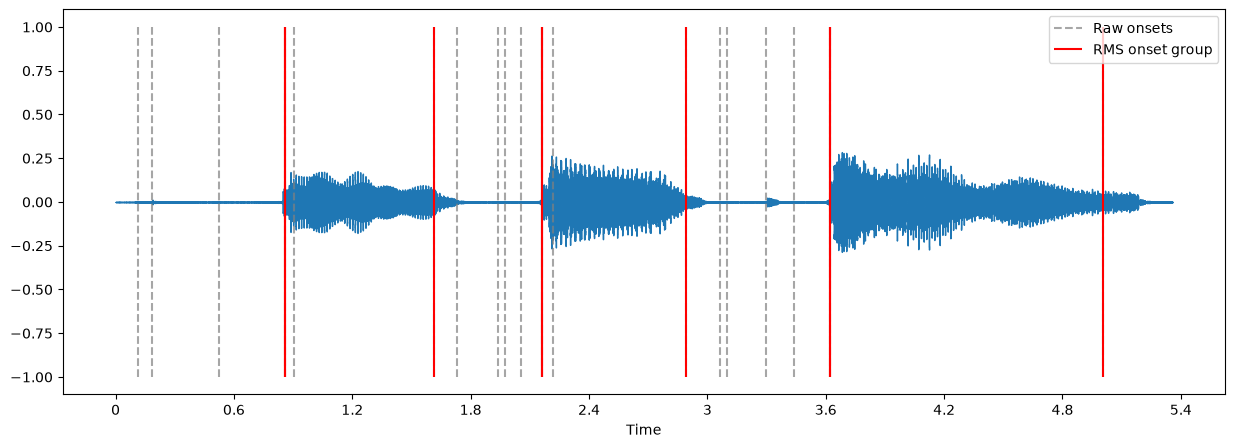

In [10]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(attack_onsets, -1, 1, color="red", linestyle="-", label="RMS onset group")
ax.set_xlabel("Time")
ax.legend()
plt.show()

Combining the logic from `get_chords()` in `chord_detect.py` with the RMS logic and appending all the results now shows a much more precise targeting on both **chord strums** and **chord transitions**. This is a valuable finding, as it now leads me into providing some feedback on the transition time between chords. 

I could use the already used librosa.frames_to_time() to get the time in seconds it took to transition to chord, and apply the concept identified by [JustinGuitar](https://www.justinguitar.com/guitar-lessons/perfect-fast-changes-b2-802) where an advanced guitar player can play one chord change per second, while a beginner should strive for a chord change roughly every two seconds

